In [53]:
import pandas as pd
df = pd.read_csv("student_clustering.csv")
df.head()

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110


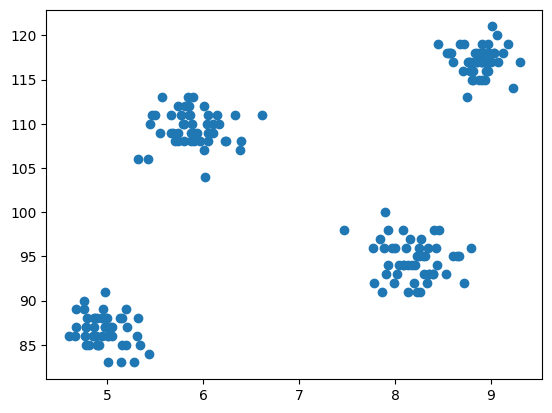

In [54]:
import matplotlib.pyplot as plt
plt.scatter(df["cgpa"], df["iq"])

In [55]:
x = df[["cgpa", "iq"]]
x

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110
...,...,...
195,4.68,89
196,8.57,118
197,5.85,112
198,6.23,108


Text(0.5, 1.0, 'Elbow Method')

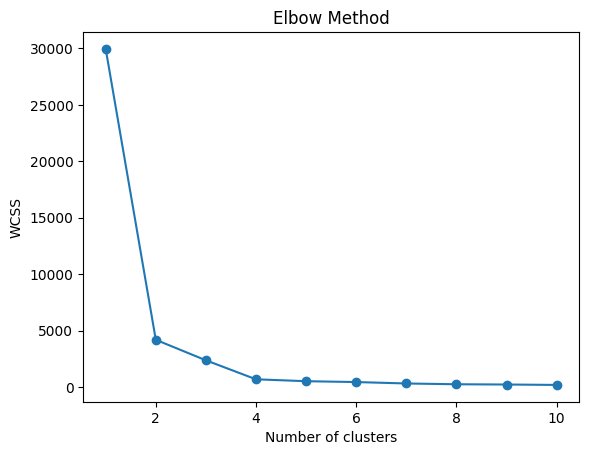

In [56]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1,11):
  kmeans = KMeans(n_clusters=i, random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

In [57]:

kmeans = KMeans(n_clusters=4,random_state=42)
y_pred = kmeans.fit_predict(x)
y_pred

array([1, 0, 2, 2, 0, 0, 2, 3, 0, 2, 1, 0, 2, 1, 0, 2, 0, 2, 0, 0, 2, 1,
       2, 1, 1, 2, 1, 3, 2, 0, 3, 0, 3, 0, 2, 2, 3, 0, 1, 0, 1, 2, 2, 1,
       3, 3, 2, 0, 3, 0, 1, 1, 3, 2, 3, 0, 0, 3, 0, 3, 0, 2, 2, 3, 1, 3,
       2, 1, 0, 2, 0, 3, 2, 1, 0, 3, 0, 3, 1, 2, 2, 3, 0, 1, 3, 1, 3, 0,
       3, 0, 3, 3, 2, 1, 2, 2, 3, 2, 1, 3, 0, 1, 1, 3, 1, 1, 2, 1, 3, 3,
       2, 3, 0, 0, 2, 3, 2, 0, 3, 1, 1, 0, 2, 3, 2, 1, 2, 0, 1, 2, 2, 0,
       1, 1, 0, 3, 0, 1, 2, 2, 2, 1, 0, 1, 1, 3, 1, 3, 0, 1, 3, 1, 3, 3,
       1, 2, 0, 3, 0, 2, 1, 3, 0, 2, 3, 1, 0, 1, 1, 3, 3, 0, 3, 1, 1, 2,
       3, 0, 1, 3, 3, 0, 0, 0, 2, 1, 2, 2, 3, 0, 2, 2, 1, 1, 2, 1, 3, 0,
       0, 3], dtype=int32)

Text(0.5, 1.0, 'K-Means Clustering')

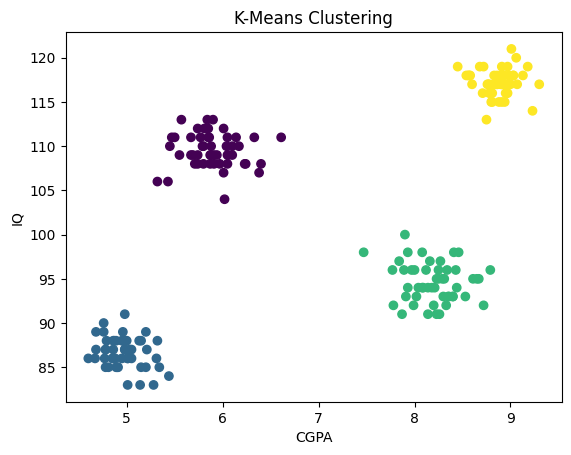

In [58]:
plt.scatter(x["cgpa"], x["iq"], c=y_pred)
plt.xlabel("CGPA")
plt.ylabel("IQ")
plt.title("K-Means Clustering")

In [59]:
df["Cluster"] = y_pred
df

,cgpa,iq,Cluster
0,5.13,88,1
1,5.90,113,0
2,8.36,93,2
3,8.27,97,2
4,5.45,110,0
...,...,...,...
195,4.68,89,1
196,8.57,118,3
197,5.85,112,0
198,6.23,108,0


In [60]:
df1=df[df["Cluster"]==0]
df2=df[df["Cluster"]==1]
df3=df[df["Cluster"]==2]
df4 = df[df["Cluster"] == 3]


In [61]:
df2

,cgpa,iq,Cluster
0,5.13,88,1
10,4.60,86,1
13,5.00,88,1
21,4.86,86,1
23,4.78,87,1
24,4.96,88,1
26,4.86,87,1
38,5.44,84,1
40,5.34,85,1
43,5.31,86,1


In [62]:
df3

,cgpa,iq,Cluster
2,8.36,93,2
3,8.27,97,2
6,8.41,98,2
9,8.09,94,2
12,8.16,97,2
15,8.31,95,2
17,7.87,91,2
20,7.47,98,2
22,7.78,92,2
25,7.93,98,2


In [63]:
df4

,cgpa,iq,Cluster
7,8.80,115,3
27,9.18,119,3
30,8.86,117,3
32,8.83,118,3
36,8.56,118,3
44,8.96,116,3
45,8.78,116,3
48,8.45,119,3
52,8.79,116,3
54,8.81,115,3


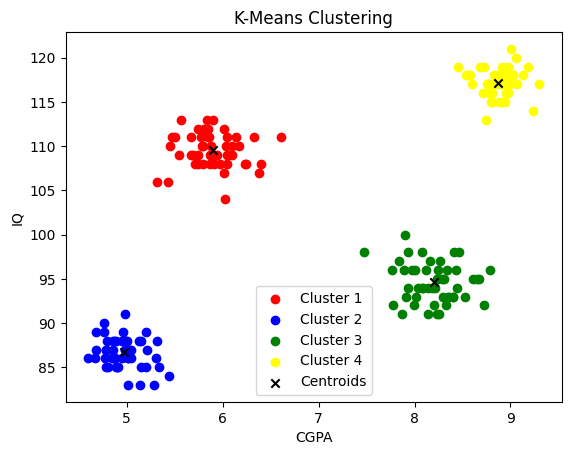

In [77]:
#print the clusters
plt.scatter(df1["cgpa"], df1["iq"], color="red", label="Cluster 1")
plt.scatter(df2["cgpa"], df2["iq"], color="blue", label="Cluster 2")
plt.scatter(df3["cgpa"], df3["iq"], color="green", label="Cluster 3")
plt.scatter(df4["cgpa"], df4["iq"], color="yellow", label="Cluster 4")

# Print centroids
plt.scatter(kmeans.cluster_centers_[:,0],
            kmeans.cluster_centers_[:,1], color="black", marker="x",label='Centroids')
plt.xlabel("CGPA")
plt.ylabel("IQ")
plt.title("K-Means Clustering")
plt.legend()
plt.show()